# EXP-001 — Chạy thử precompute trọng số AU
Notebook độc lập (runtime mới). Mỗi lần thử: **copy notebook này, đổi `RUN_NAME`** ở cell Cấu hình.
Kết quả lưu ở `ExpCLIP_output/exp001/<RUN_NAME>/` trên Drive.

# Cấu hình

In [1]:
RUN_NAME = "test01_limit50"   # đổi tên cho mỗi lần thử
LIMIT = 50                    # 0 = toàn bộ ảnh
BRANCH = "exp/001-au-detector-filtering"

# tham số stage weight (đổi để thử, không cần chạy lại stage 1-2)
SCORE = "jaccard"             # jaccard | precision
THRESHOLD = 0.5               # ngưỡng xác suất AU
W_MIN = 0.1

INSTRUCTION = "Please play the role of a facial action describer. Objectively describe the detailed facial actions of the person in the image."
TRAIN_DATA = "/content/CAER-S_Face/train"
FACE_ZIP = "/content/drive/MyDrive/Datasets/CAERS_Face_train.zip"
EXP_DIR = f"/content/drive/MyDrive/ExpCLIP_output/exp001/{RUN_NAME}"
T5_CACHE = "/root/.cache/huggingface/hub/models--google--flan-t5-xxl"

import os, subprocess
def run(cmd):
    """Chạy lệnh shell, in output trực tiếp; lỗi thì dừng cell (khác với `!`)."""
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         env={**os.environ, "PYTHONUNBUFFERED": "1"})  # in log ngay, không đợi hết
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"Lệnh lỗi (exit {p.returncode}) — xem output ở trên")

# Mount Drive & GPU

In [2]:
import os
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(EXP_DIR, exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


# Clone repo (nhánh EXP-001)

In [3]:
if not os.path.isdir("/content/Exp-CLIP"):
    !git clone -b $BRANCH https://github.com/huongng389/Exp-CLIP.git /content/Exp-CLIP
%cd /content/Exp-CLIP
!git checkout $BRANCH && git pull
!git log --oneline -1   # ghi lại commit vào research_log

Cloning into '/content/Exp-CLIP'...
remote: Enumerating objects: 357, done.
remote: Counting objects: 100% (357/357), done.
remote: Compressing objects: 100% (100/100), done.
remote: Total 357 (delta 266), reused 344 (delta 254), pack-reused 0 (from 0)
Receiving objects: 100% (357/357), 30.66 MiB | 19.60 MiB/s, done.
Resolving deltas: 100% (266/266), done.
/content/Exp-CLIP
Already on 'exp/001-au-detector-filtering'
Your branch is up to date with 'origin/exp/001-au-detector-filtering'.
Already up to date.
da10266 (HEAD -> exp/001-au-detector-filtering, origin/exp/001-au-detector-filtering) EXP-001: add AU-based weight precompute script


# Giải nén CAER-S đã crop mặt

In [4]:
!mkdir -p /content/CAER-S_Face
!unzip -q -n "$FACE_ZIP" -d /content/CAER-S_Face
!ls /content/CAER-S_Face/train

Angry  Disgust	Fear  Happy  Neutral  Sad  Surprise


# Cài dependencies
`venv310`: torch 2.0.1 + lavis (stage 1, 3). `venv_feat`: py-feat (stage 2) — tách riêng để không đụng torch.

In [5]:
!sudo apt-get -qq update > /dev/null
!sudo apt-get -qq install -y python3.10 python3.10-venv python3.10-distutils > /dev/null
!python3.10 -m venv /content/venv310
!/content/venv310/bin/pip install -q --upgrade pip
!/content/venv310/bin/pip install -q torch==2.0.1 torchvision==0.15.2 torchaudio==2.0.2 --index-url https://download.pytorch.org/whl/cu118
!/content/venv310/bin/pip install -q transformers tqdm regex pyyaml pandas pydantic click timm einops
!/content/venv310/bin/pip install -q salesforce-lavis
# phải cài SAU lavis: lavis kéo numpy 2.x / opencv mới
!/content/venv310/bin/pip install -q "numpy<2" "opencv-python==4.10.0.84" "opencv-python-headless==4.10.0.84"
!/content/venv310/bin/python -c "import numpy, torch, lavis; print('numpy', numpy.__version__, '| torch', torch.__version__, '| cuda', torch.cuda.is_available())"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 7.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 36.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Instal

In [6]:
!python3.10 -m venv /content/venv_feat
!/content/venv_feat/bin/pip install -q --upgrade pip
!/content/venv_feat/bin/pip install -q py-feat==0.6.2
# py-feat 0.6.x chưa hỗ trợ numpy 2 và scipy mới (scipy 1.14 bỏ hàm `simps`)
!/content/venv_feat/bin/pip install -q "numpy<2" "scipy<1.14"
!MPLBACKEND=Agg /content/venv_feat/bin/python -c "import feat, torch; print('py-feat', feat.__version__, '| torch', torch.__version__, '| cuda', torch.cuda.is_available())"

Traceback (most recent call last):
  File "<string>", line 1, in <module>
  File "/content/venv_feat/lib/python3.10/site-packages/feat/__init__.py", line 11, in <module>
    from .data import Fex
  File "/content/venv_feat/lib/python3.10/site-packages/feat/data.py", line 25, in <module>
    from torchvision.io import read_image, read_video
ImportError: cannot import name 'read_video' from 'torchvision.io' (/content/venv_feat/lib/python3.10/site-packages/torchvision/io/__init__.py)


In [11]:
# Stage 1 đã xong, không cần FlanT5 trong cache nữa
!rm -rf /root/.cache/huggingface /root/.cache/pip /content/venv_feat
!df -h /content | tail -1
!python3.10 -m venv /content/venv_feat
!/content/venv_feat/bin/pip install -q --upgrade pip
!/content/venv_feat/bin/pip install -q --no-cache-dir py-feat==0.6.2 torch==2.2.2 torchvision==0.17.2 "numpy<2" "scipy<1.14" \
  --extra-index-url https://download.pytorch.org/whl/cu121
!MPLBACKEND=Agg /content/venv_feat/bin/python -c "import feat, torch, torchvision; from feat import Detector; print('py-feat', feat.__version__, '| torchvision', torchvision.__version__, '| torch', torch.__version__, '| cuda', torch.cuda.is_available())"

overlay         113G   53G   61G  47% /
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 35.0 MB/s eta 0:00:00
py-feat 0.6.2 | torchvision 0.17.2+cu121 | torch 2.2.2+cu121 | cuda True


# Stage 1 — Sinh câu mô tả (BLIP-2 FlanT5-XXL)

In [7]:
os.environ["HF_HUB_OFFLINE"] = "1" if os.path.isdir(T5_CACHE) else "0"
run(f'/content/venv310/bin/python tools/precompute_au_weights.py caption '
    f'--train-data {TRAIN_DATA} --out-dir {EXP_DIR} --limit {LIMIT} --batch-size 16 '
    f'--instruction "{INSTRUCTION}"')

100 done, 50 to caption
/content/venv310/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(

  0%|          | 0.00/1.89G [00:00<?, ?B/s]
  0%|          | 48.0k/1.89G [00:00<2:27:11, 229kB/s]
  0%|          | 80.0k/1.89G [00:00<2:48:32, 200kB/s]
  0%|          | 160k/1.89G [00:00<1:40:21, 336kB/s] 
  0%|          | 240k/1.89G [00:00<1:14:15, 454kB/s]
  0%|          | 352k/1.89G [00:00<52:52, 638kB/s]  
  0%|          | 528k/1.89G [00:00<35:49, 942kB/s]
  0%|          | 760k/1.89G [00:00<25:06, 1.34MB/s]
  0%|          | 1.11M/1.89G [00:01<16:29, 2.05MB/s]
  0%|          | 1.61M/1.89G [00:01<11:22, 2.96MB/s]
  0%|          | 2.41M/1.89G [00:01<07:24, 4.55MB/s]
  0%|          | 3.62M/1.89G [00:01<04:53, 6.89MB/s]
  0%|          | 5.36M/1.89G [00:01<03:17, 10.2MB/s]
  0%| 

# Stage 2 — Phát hiện AU (py-feat xgb)

In [12]:
# MPLBACKEND=Agg: venv_feat không có backend inline của notebook, matplotlib sẽ báo lỗi khi import feat
run(f'MPLBACKEND=Agg /content/venv_feat/bin/python tools/precompute_au_weights.py au '
    f'--train-data {TRAIN_DATA} --out-dir {EXP_DIR} --limit {LIMIT} --batch-size 16')

0 done, 50 to detect

100%|██████████| 1786259/1786259 [00:00<00:00, 185081849.52it/s]

100%|██████████| 12281146/12281146 [00:00<00:00, 244967850.79it/s]

100%|██████████| 965545/965545 [00:00<00:00, 117908092.58it/s]

100%|██████████| 33635572/33635572 [00:00<00:00, 313261213.85it/s]

100%|██████████| 130263/130263 [00:00<00:00, 38191152.10it/s]

100%|██████████| 45886076/45886076 [00:00<00:00, 407178298.74it/s]

100%|██████████| 130263/130263 [00:00<00:00, 46502904.24it/s]

100%|██████████| 53851068/53851068 [00:00<00:00, 431441361.09it/s]

100%|██████████| 130263/130263 [00:00<00:00, 40188497.39it/s]

100%|██████████| 166975/166975 [00:00<00:00, 55463998.61it/s]

100%|██████████| 530776/530776 [00:00<00:00, 77032384.08it/s]

100%|██████████| 493515/493515 [00:00<00:00, 99383135.13it/s]

100%|██████████| 207163/207163 [00:00<00:00, 44990659.12it/s]

100%|██████████| 1151853/1151853 [00:00<00:00, 169635591.48it/s]

100%|██████████| 572282/572282 [00:00<00:00, 76543406.41it/s]

100%|█

# Stage 3 — Tính trọng số

In [13]:
run(f'/content/venv310/bin/python tools/precompute_au_weights.py weight --out-dir {EXP_DIR} '
    f'--score {SCORE} --threshold {THRESHOLD} --w-min {W_MIN}')

150 images, 100 without detected face (w=1.0)
weight mean 0.720, median 1.000, == w_min: 35
score == 0 (caption fully contradicts detector): 35


# Kiểm tra kết quả

In [14]:
import pandas as pd
from collections import Counter
pd.set_option("display.max_colwidth", 200)

dbg = pd.read_csv(f"{EXP_DIR}/au_weights_debug.csv").fillna("")
print(dbg["weight"].describe(), "\n")

cnt = lambda col: Counter(g for s in dbg[col] for g in s.split())
print("Text:    ", cnt("text_groups").most_common())
print("Detector:", cnt("detected_groups").most_common())
print("Câu không bắt được nhóm AU nào:", (dbg["text_groups"] == "").sum(), "/", len(dbg))

dbg.sort_values("weight")[["path", "weight", "text_groups", "detected_groups", "caption"]]

count    150.000000
mean       0.720444
std        0.402422
min        0.100000
25%        0.200000
50%        1.000000
75%        1.000000
max        1.000000
Name: weight, dtype: float64 

Text:     [('brow_lower', 69), ('dimpler', 15), ('lip_corner_pull', 8), ('upper_lid_raise', 4), ('lid_tight', 3), ('eyes_closed', 2)]
Detector: [('lip_press', 36), ('mouth_open', 27), ('brow_lower', 21), ('lip_corner_depress', 18), ('lip_stretch', 17), ('dimpler', 15), ('brow_raise', 14), ('upper_lid_raise', 11), ('lid_tight', 10), ('eyes_closed', 7), ('nose_wrinkle', 2), ('lip_corner_pull', 1)]
Câu không bắt được nhóm AU nào: 57 / 150


,path,weight,text_groups,detected_groups,caption
0,Angry/0001.png,0.1,brow_lower,eyes_closed lip_stretch mouth_open,he has a frown on his face
1,Angry/0002.png,0.1,brow_lower,lip_press,he has a frown on his face
2,Angry/0003.png,0.1,brow_lower,lip_press,he has a frown on his face
5,Angry/0006.png,0.1,brow_lower,brow_raise lip_corner_depress lip_stretch mouth_open,he has a frown on his face
12,Angry/0013.png,0.1,,dimpler lip_corner_depress lip_press upper_lid_raise,she has a sad look on her face
...,...,...,...,...,...
145,Angry/0146.png,1.0,brow_lower,,he has a frown on his face
146,Angry/0147.png,1.0,brow_lower,,he has a frown on his face
147,Angry/0148.png,1.0,brow_lower,,he has a frown on his face
148,Angry/0149.png,1.0,brow_lower,,he has a frown on his face


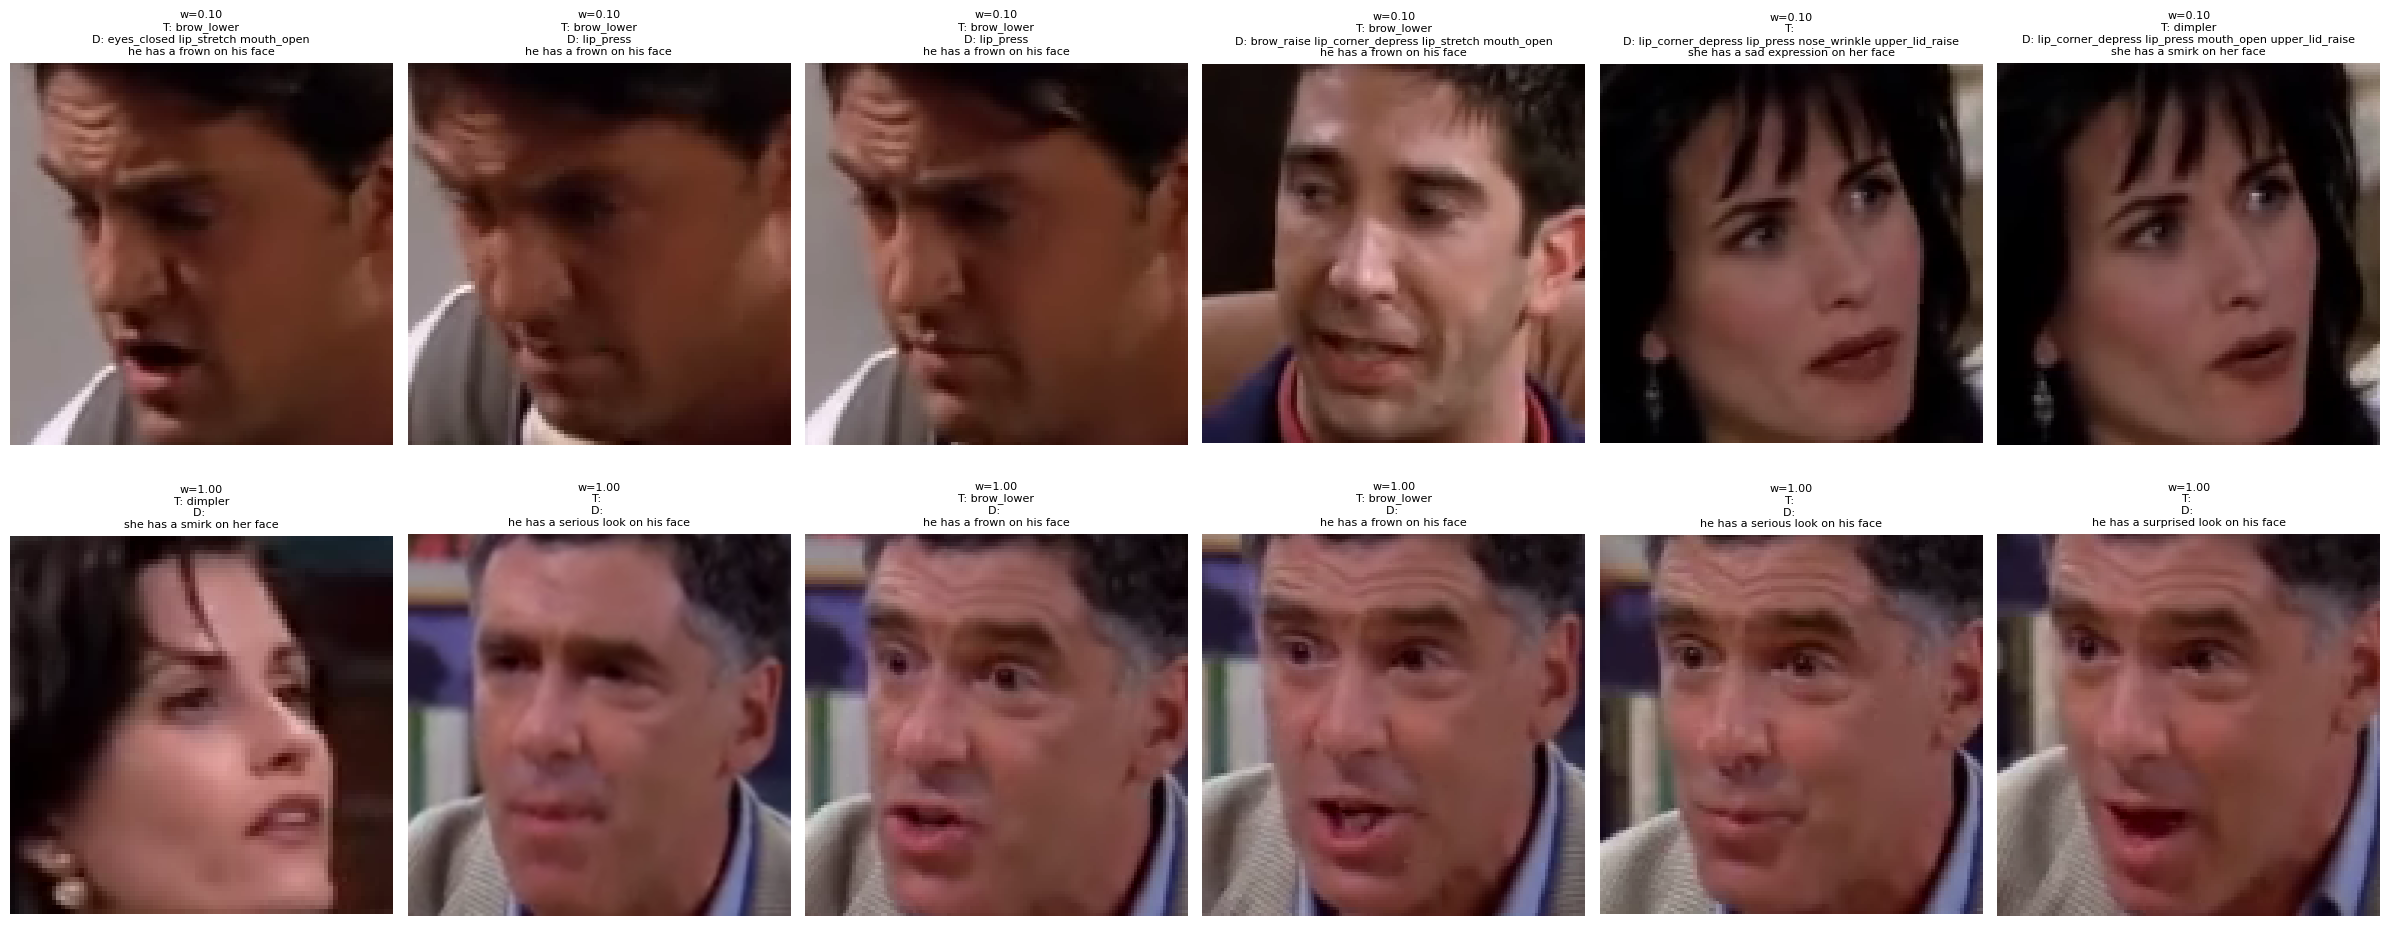

In [15]:
import matplotlib.pyplot as plt, textwrap
from PIL import Image

show = pd.concat([dbg.nsmallest(6, "weight"), dbg.nlargest(6, "weight")])
fig, axes = plt.subplots(2, 6, figsize=(24, 10))
for ax, (_, r) in zip(axes.flat, show.iterrows()):
    ax.imshow(Image.open(f"{TRAIN_DATA}/{r.path}").convert("RGB"))
    ax.set_title(f"w={r.weight:.2f}\nT: {r.text_groups}\nD: {r.detected_groups}\n"
                 + "\n".join(textwrap.wrap(r.caption, 40)), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{EXP_DIR}/samples.png", dpi=80)
plt.show()

# Liệt kê file kết quả trên Drive

In [16]:
!ls -lh "$EXP_DIR"

total 952K
-rw------- 1 root root 7.9K Oct 13 07:31 aus.csv
-rw------- 1 root root  13K Oct 13 07:31 au_weights_debug.csv
-rw------- 1 root root 3.4K Oct 13 07:31 au_weights.json
-rw------- 1 root root  12K Oct 13 07:17 captions.jsonl
-rw------- 1 root root 915K Oct 13 07:31 samples.png
